In [1]:
import os
import cv2
import argparse
from ultralytics  import YOLO
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from analyze_errors.matching import match_gt_with_results
from analyze_errors.metrics_calculate import compute_map, box_metrics_calculate, frame_level_metrics, compute_map_coco_style
from analyze_errors.visualization import visualize_prediction
from analyze_errors.eigen_cam import EigenCAM, visualize_prediction_with_cam, only_eigencam_visualizate

# === parameters ===
RANDOM_STATE = 42

In [2]:
# === parameters ===
path2data_file = "./data_v2.yaml"
split = "val"
path2model = "runs/detect/baseline_n_v0/non_aug_detect/weights/best.pt"
path2model_v1 = "runs/detect/baseline_n_v1/aug_clahe/weights/best.pt"
path2model_v2 = "runs/detect/baseline_n_v2/aug_frangi/weights/best.pt"
imgsize = 512
project = "baseline_v0"
exp_name = "errors_analyze_overfitting_clahe"
conf = 0.001

nms_iou = 0.6
match_iou = 0.5

batch_size = 32

In [3]:
# === model init ===
model = YOLO(path2model_v2)

In [4]:
source_baseline_v0 = "./dataset_yolo/val_fold_1_s.txt"
source_baseline_v1 = "./dataset_v1/val_fold_1_s.txt"
source_baseline_v2 = "./dataset_v2/val_fold_1_s.txt"

results = model.predict(
    source=source_baseline_v2,
    imgsz=imgsize,
    batch=batch_size,
    workers=2,
    seed=RANDOM_STATE,
    deterministic=True,
    conf=conf, # 0.0001 # низкий порог для честного расчёта mAP
    iou=nms_iou, # IoU для NMS при валидации
    verbose=False # Отключить печать
)

In [5]:
eigencam = EigenCAM(model, target_layer_idx=15)   # P5; для мелких объектов попробуй 15 (P3)

### mAP calculate

In [6]:
m = compute_map(results, "./dataset_v2/labels", num_classes=1)
print(f"mAP0.5: {m['map_05']:0.4f}")
print(f"mAP0.5-0.95: {m['map_50_95']:.4f}")
print(m)

mAP0.5: 0.7624
mAP0.5-0.95: 0.4812
{'ap_table': array([[    0.76242,     0.74222,     0.72414,     0.69337,     0.64866,     0.57045,     0.40632,     0.20277,    0.056476,   0.0056491]]), 'map_05': 0.7624227059705667, 'map_50_95': 0.4812488525641313, 'per_iou_map': {0.5: 0.7624227059705667, 0.55: 0.7422155985337713, 0.6000000000000001: 0.724142064868696, 0.6500000000000001: 0.6933699141283578, 0.7000000000000002: 0.6486640436650124, 0.7500000000000002: 0.5704535543462295, 0.8000000000000003: 0.406321550330587, 0.8500000000000003: 0.20277357825015213, 0.9000000000000004: 0.05647641609687147, 0.9500000000000004: 0.0056490994510678145}, 'per_class_ap_05': {0: 0.7624227059705667}}


In [7]:
coco_m = compute_map_coco_style(results, "./dataset_v2/labels", num_classes=1)
print(f"mAP0.5: {coco_m['map_05']}")
print(f"mAP0.5-0.95: {coco_m['map_50_95']}")
print(coco_m)

mAP0.5: 0.7633086442947388
mAP0.5-0.95: 0.48142752051353455
{'ap_table': array([[    0.76331,     0.74253,      0.7246,      0.6935,     0.64866,     0.57045,     0.40632,     0.20277,    0.056476,   0.0056491]], dtype=float32), 'map_05': 0.7633086442947388, 'map_50_95': 0.48142752051353455, 'per_iou_map': {0.5: 0.7633086442947388, 0.550000011920929: 0.7425336241722107, 0.6000000238418579: 0.72459876537323, 0.6499999761581421: 0.6934979557991028, 0.699999988079071: 0.6486640572547913, 0.75: 0.5704535245895386, 0.800000011920929: 0.40631967782974243, 0.8500000238418579: 0.2027735710144043, 0.8999999761581421: 0.0564764179289341, 0.949999988079071: 0.005649099592119455}, 'per_class_ap_05': {0: 0.7633086442947388}, 'gt_count': array([1693])}


In [8]:
frame_m = frame_level_metrics(results, "./dataset_v2/labels")
for item in frame_m:
    print(f"{item}: {frame_m[item]:.4f}")

sensitivity: 0.8439
specificity: 0.9943
precision: 0.9975
recall: 0.8439
f1: 0.9143
accuracy: 0.8851
tp: 784.0000
fp: 2.0000
fn: 145.0000
tn: 348.0000


### TP, FP, FN, Precision, Recall for GT

In [9]:
boxes_metrics = []
for c in np.linspace(0.05, 0.9, 18):
    m = box_metrics_calculate(results, "./dataset_yolo/labels", iou=match_iou, conf=c)
    boxes_metrics.append({
        "conf": c,
        "iou": match_iou,
        "metrics": m 
    })

In [10]:
for item in boxes_metrics:
    ii = item['metrics']
    print(f"conf: {item['conf']:.2f}, | TP: {ii['TP']} | FP: {ii['FP']} | FN: {ii['FN']} | P: {ii['P']:.4f} R: {ii['R']:.4f} | F1: {ii['F1']:.4f}")

conf: 0.05, | TP: 1147 | FP: 259 | FN: 546 | P: 0.8158 R: 0.6775 | F1: 0.7402
conf: 0.10, | TP: 1138 | FP: 191 | FN: 555 | P: 0.8563 R: 0.6722 | F1: 0.7531
conf: 0.15, | TP: 1127 | FP: 158 | FN: 566 | P: 0.8770 R: 0.6657 | F1: 0.7569
conf: 0.20, | TP: 1114 | FP: 126 | FN: 579 | P: 0.8984 R: 0.6580 | F1: 0.7596
conf: 0.25, | TP: 1107 | FP: 105 | FN: 586 | P: 0.9134 R: 0.6539 | F1: 0.7621
conf: 0.30, | TP: 1097 | FP: 85 | FN: 596 | P: 0.9281 R: 0.6480 | F1: 0.7631
conf: 0.35, | TP: 1090 | FP: 70 | FN: 603 | P: 0.9397 R: 0.6438 | F1: 0.7641
conf: 0.40, | TP: 1081 | FP: 63 | FN: 612 | P: 0.9449 R: 0.6385 | F1: 0.7621
conf: 0.45, | TP: 1071 | FP: 51 | FN: 622 | P: 0.9545 R: 0.6326 | F1: 0.7609
conf: 0.50, | TP: 1064 | FP: 42 | FN: 629 | P: 0.9620 R: 0.6285 | F1: 0.7603
conf: 0.55, | TP: 1054 | FP: 35 | FN: 639 | P: 0.9679 R: 0.6226 | F1: 0.7577
conf: 0.60, | TP: 1034 | FP: 26 | FN: 659 | P: 0.9755 R: 0.6108 | F1: 0.7512
conf: 0.65, | TP: 1008 | FP: 17 | FN: 685 | P: 0.9834 R: 0.5954 | F1: 0

### Visualization

In [52]:
# 40, 50, 1200, 950, 770
result_item = results[770]
stem = result_item.path.split("\\")[-1].split('.')[0]
print(stem)
path2label = f"./dataset_v2/labels/{stem}.txt"

# un_gt - idx для FN (из GT) - то есть можно сопоставить с теми, которые не были найдены
matches, un_gt, un_pred, gt = match_gt_with_results(
    result_item, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

p40_v6_00024


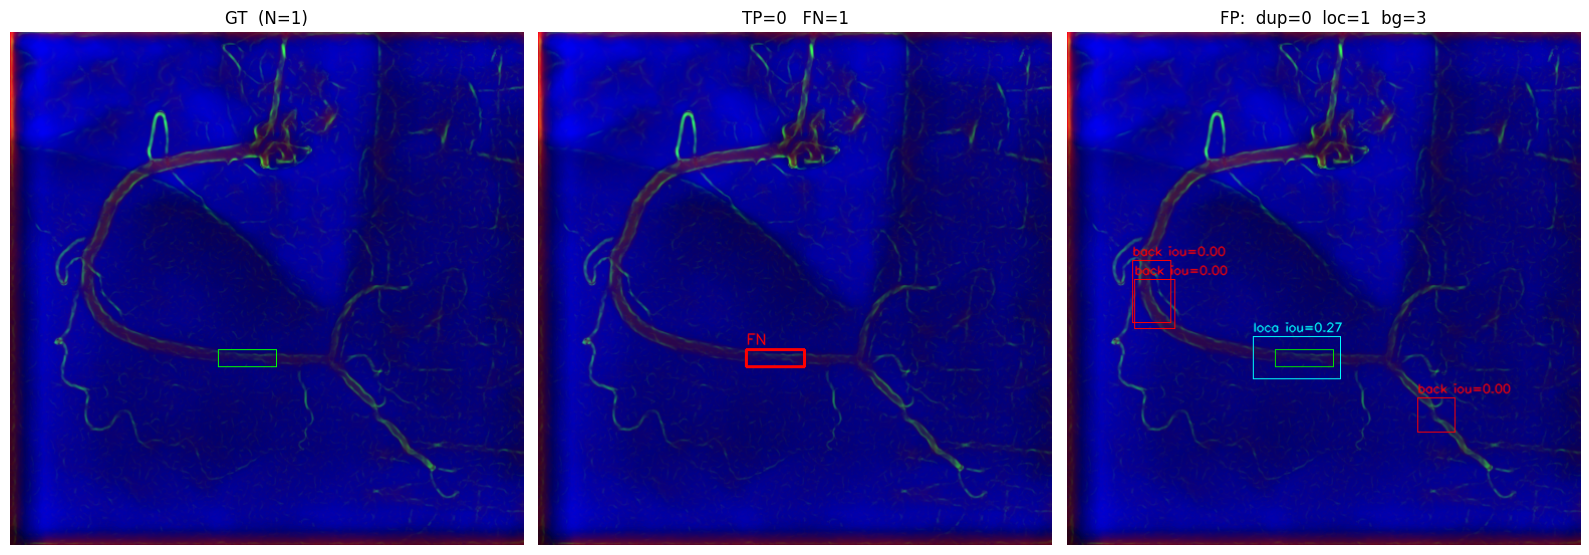

In [53]:
visualize_prediction(
    result_item, matches, un_gt, un_pred, gt
)

### EigenCAM visualization

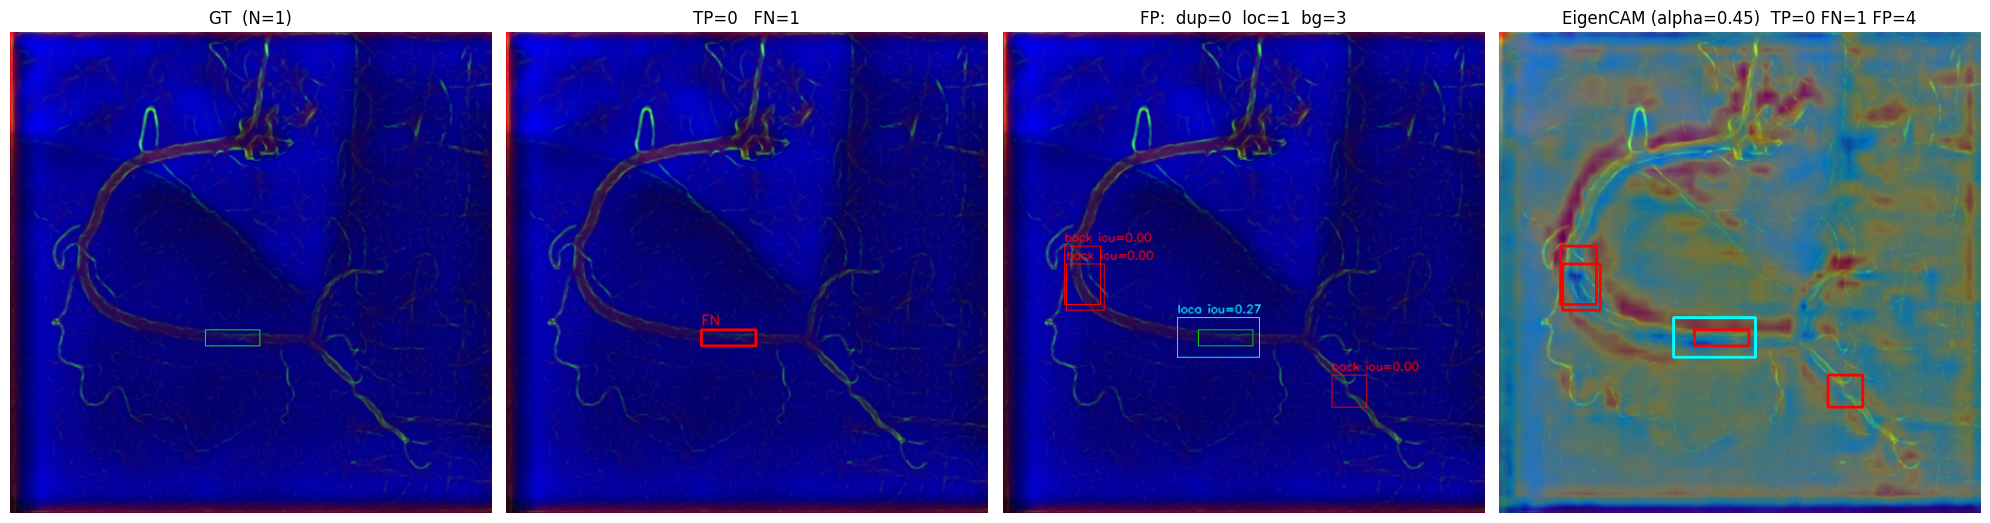

In [54]:
result_cam, heatmap, feat_shape = eigencam(result_item.path, imgsz=imgsize)

matches, un_gt, un_pred, gt = match_gt_with_results(
    result_cam, path2label, iou_thresh=match_iou, conf_thresh=conf, return_gt=True
)

visualize_prediction_with_cam(result_cam, matches, un_gt, un_pred, gt, heatmap, alpha=0.45, figsize=(20, 15))

In [55]:
img_path = f"./dataset_yolo/images/{stem}.png"
img_i = cv2.imread(img_path)
img_i = cv2.cvtColor(img_i, cv2.COLOR_BGR2RGB)

result_cam.orig_img = img_i

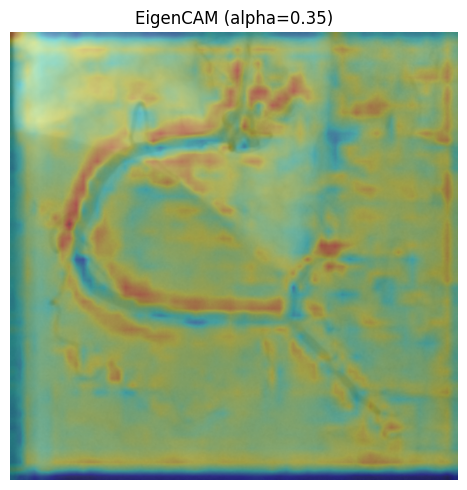

In [56]:
only_eigencam_visualizate(result_cam, heatmap, alpha=0.35, figsize=(9, 5))